In [ ]:
# !pip install --upgrade --force-reinstall tensorflow-datasets

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.3/5.3 MB 94.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.8/3.8 MB 134.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.7/15.7 MB 130.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 55.0/55.0 MB 71.9 MB/s  0:00:00
  Created wheel for promise: filename=promise-2.3-py3-none-any.whl size=21581 sha256=e1a225719c3a29037b376f4a6db7700b779586bda93d701f62b3c29420181781
  Stored in directory: /root/.cache/pip/wheels/8f/46/1c/1f4e5d73a20eb816ead5014e97cdeb3928cf314fc46c7bab61
Successfully built promise
  Attempting uninstall: zipp
    Found existing installation: zipp 4.1.2
    Uninstalling zipp-4.1.2:
      Successfully uninstalled zipp-4.1.2
  Attempting uninstall: wrapt
    Found existing installation: wrapt 2.5.2
    Uninstalling wrapt-2.5.2:
      Successfully uninstalled

In [1]:
# Pobieranie zestawu danych, tworzenie zbioru treningowego, walidacyjnego i testowego

# Instalacja zależności i importy
!pip install -U importlib_resources
import importlib_resources
import tensorflow_datasets as tfds
import tensorflow as tf

# Pobierabie zbioru Caltech-UCSD Birds-200-2011
dataset, info = tfds.load(
    "caltech_birds2011",
    split=["train", "test"],
    as_supervised=True,
    with_info=True
)
train_ds, test_ds = dataset

# Tworzenie zbiorów
num_train = info.splits["train"].num_examples
num_test = info.splits["test"].num_examples

VALIDATION_SPLIT = 0.1
num_val = int(num_train * VALIDATION_SPLIT)

val_ds = train_ds.take(num_val)
train_ds = train_ds.skip(num_val)

print(info)

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/2 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/caltech_birds2011/incomplete.XHUEHZ_0.2.0/caltech_birds2011-train.tfrecord…

Generating test examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/caltech_birds2011/incomplete.XHUEHZ_0.2.0/caltech_birds2011-test.tfrecord-…

Dataset caltech_birds2011 downloaded and prepared to /root/tensorflow_datasets/caltech_birds2011/0.2.0. Subsequent calls will reuse this data.
tfds.core.DatasetInfo(
    name='caltech_birds2011',
    full_name='caltech_birds2011/0.2.0',
    description="""
    Caltech-UCSD Birds 200 (CUB-200) is an image dataset with photos 
    of 200 bird species (mostly North American). The total number of 
    categories of birds is 200 and there are 6033 images in the 2010 
    dataset and 11,788 images in the 2011 dataset.
    Annotations include bounding boxes, segmentation labels.
    """,
    homepage='https://www.vision.caltech.edu/datasets/cub_200_2011/',
    data_dir='/root/tensorflow_datasets/caltech_birds2011/0.2.0',
    file_format=tfrecord,
    download_size=1.11 GiB,
    dataset_size=1.11 GiB,
    features=FeaturesDict({
        'bbox': BBoxFeature(shape=(4,), dtype=float32),
        'image': Image(shape=(None, None, 3), dtype=uint8),
        'image/filename': Text(shape=(), dtype=stri

In [2]:
# Lista zawierająca nazwy gatunków ptaków z zestawu danych

bird_species = [
    "Black_footed_Albatross",
    "Laysan_Albatross",
    "Sooty_Albatross",
    "Groove_billed_Ani",
    "Crested_Auklet",
    "Least_Auklet",
    "Parakeet_Auklet",
    "Rhinoceros_Auklet",
    "Brewer_Blackbird",
    "Red_winged_Blackbird",
    "Rusty_Blackbird",
    "Yellow_headed_Blackbird",
    "Bobolink",
    "Indigo_Bunting",
    "Lazuli_Bunting",
    "Painted_Bunting",
    "Cardinal",
    "Spotted_Catbird",
    "Gray_Catbird",
    "Yellow_breasted_Chat",
    "Eastern_Towhee",
    "Chuck_will_Widow",
    "Brandt_Cormorant",
    "Red_faced_Cormorant",
    "Pelagic_Cormorant",
    "Bronzed_Cowbird",
    "Shiny_Cowbird",
    "Brown_Creeper",
    "American_Crow",
    "Fish_Crow",
    "Black_billed_Cuckoo",
    "Mangrove_Cuckoo",
    "Yellow_billed_Cuckoo",
    "Gray_crowned_Rosy_Finch",
    "Purple_Finch",
    "Northern_Flicker",
    "Acadian_Flycatcher",
    "Great_Crested_Flycatcher",
    "Least_Flycatcher",
    "Olive_sided_Flycatcher",
    "Scissor_tailed_Flycatcher",
    "Vermilion_Flycatcher",
    "Yellow_bellied_Flycatcher",
    "Frigatebird",
    "Northern_Fulmar",
    "Gadwall",
    "American_Goldfinch",
    "European_Goldfinch",
    "Boat_tailed_Grackle",
    "Eared_Grebe",
    "Horned_Grebe",
    "Pied_billed_Grebe",
    "Western_Grebe",
    "Blue_Grosbeak",
    "Evening_Grosbeak",
    "Pine_Grosbeak",
    "Rose_breasted_Grosbeak",
    "Pigeon_Guillemot",
    "California_Gull",
    "Glaucous_winged_Gull",
    "Heermann_Gull",
    "Herring_Gull",
    "Ivory_Gull",
    "Ring_billed_Gull",
    "Slaty_backed_Gull",
    "Western_Gull",
    "Anna_Hummingbird",
    "Ruby_throated_Hummingbird",
    "Rufous_Hummingbird",
    "Green_Violetear",
    "Long_tailed_Jaeger",
    "Pomarine_Jaeger",
    "Blue_Jay",
    "Florida_Jay",
    "Green_Jay",
    "Dark_eyed_Junco",
    "Tropical_Kingbird",
    "Gray_Kingbird",
    "Belted_Kingfisher",
    "Green_Kingfisher",
    "Pied_Kingfisher",
    "Ringed_Kingfisher",
    "White_breasted_Kingfisher",
    "Red_legged_Kittiwake",
    "Horned_Lark",
    "Pacific_Loon",
    "Mallard",
    "Western_Meadowlark",
    "Hooded_Merganser",
    "Red_breasted_Merganser",
    "Mockingbird",
    "Nighthawk",
    "Clark_Nutcracker",
    "White_breasted_Nuthatch",
    "Baltimore_Oriole",
    "Hooded_Oriole",
    "Orchard_Oriole",
    "Scott_Oriole",
    "Ovenbird",
    "Brown_Pelican",
    "White_Pelican",
    "Western_Wood_Pewee",
    "Sayornis",
    "American_Pipit",
    "Whip_poor_Will",
    "Horned_Puffin",
    "Common_Raven",
    "White_necked_Raven",
    "American_Redstart",
    "Geococcyx",
    "Loggerhead_Shrike",
    "Great_Grey_Shrike",
    "Baird_Sparrow",
    "Black_throated_Sparrow",
    "Brewer_Sparrow",
    "Chipping_Sparrow",
    "Clay_colored_Sparrow",
    "House_Sparrow",
    "Field_Sparrow",
    "Fox_Sparrow",
    "Grasshopper_Sparrow",
    "Harris_Sparrow",
    "Henslow_Sparrow",
    "Le_Conte_Sparrow",
    "Lincoln_Sparrow",
    "Nelson_Sharp_tailed_Sparrow",
    "Savannah_Sparrow",
    "Seaside_Sparrow",
    "Song_Sparrow",
    "Tree_Sparrow",
    "Vesper_Sparrow",
    "White_crowned_Sparrow",
    "White_throated_Sparrow",
    "Cape_Glossy_Starling",
    "Bank_Swallow",
    "Barn_Swallow",
    "Cliff_Swallow",
    "Tree_Swallow",
    "Scarlet_Tanager",
    "Summer_Tanager",
    "Artic_Tern",
    "Black_Tern",
    "Caspian_Tern",
    "Common_Tern",
    "Elegant_Tern",
    "Forsters_Tern",
    "Least_Tern",
    "Green_tailed_Towhee",
    "Brown_Thrasher",
    "Sage_Thrasher",
    "Black_capped_Vireo",
    "Blue_headed_Vireo",
    "Philadelphia_Vireo",
    "Red_eyed_Vireo",
    "Warbling_Vireo",
    "White_eyed_Vireo",
    "Yellow_throated_Vireo",
    "Bay_breasted_Warbler",
    "Black_and_white_Warbler",
    "Black_throated_Blue_Warbler",
    "Blue_winged_Warbler",
    "Canada_Warbler",
    "Cape_May_Warbler",
    "Cerulean_Warbler",
    "Chestnut_sided_Warbler",
    "Golden_winged_Warbler",
    "Hooded_Warbler",
    "Kentucky_Warbler",
    "Magnolia_Warbler",
    "Mourning_Warbler",
    "Myrtle_Warbler",
    "Nashville_Warbler",
    "Orange_crowned_Warbler",
    "Palm_Warbler",
    "Pine_Warbler",
    "Prairie_Warbler",
    "Prothonotary_Warbler",
    "Swainson_Warbler",
    "Tennessee_Warbler",
    "Wilson_Warbler",
    "Worm_eating_Warbler",
    "Yellow_Warbler",
    "Northern_Waterthrush",
    "Louisiana_Waterthrush",
    "Bohemian_Waxwing",
    "Cedar_Waxwing",
    "American_Three_toed_Woodpecker",
    "Pileated_Woodpecker",
    "Red_bellied_Woodpecker",
    "Red_cockaded_Woodpecker",
    "Red_headed_Woodpecker",
    "Downy_Woodpecker",
    "Bewick_Wren",
    "Cactus_Wren",
    "Carolina_Wren",
    "House_Wren",
    "Marsh_Wren",
    "Rock_Wren",
    "Winter_Wren",
    "Common_Yellowthroat",
]

print(len(bird_species))

200


In [3]:
# Dostosowanie obrazów do wymagań sieci

IMG_SIZE = (224,224)

def preprocess(image, label):
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32)

    return image, label

In [4]:
# Przygotowanie zbiorów treningowego, walidacyjnego i testowego

# Rozmiar paczki
BATCH_SIZE = 64

# Przetwarzanie każdego zdjęcia
train_ds = train_ds.map(
    preprocess,
    num_parallel_calls=tf.data.AUTOTUNE
)

val_ds = val_ds.map(
    preprocess,
    num_parallel_calls=tf.data.AUTOTUNE
)

test_ds = test_ds.map(
    preprocess,
    num_parallel_calls=tf.data.AUTOTUNE
)

# Grupowanie w paczki
train_ds = train_ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
val_ds = val_ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
test_ds = test_ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

In [5]:
# Wypisanie zestawu danych
print(f"Liczba klas: {len(bird_species)}")
print(f"Liczba obrazów w zbiorze treningowym: {num_train}")
print(f"Liczba obrazów w zbiorze walidacyjnym: {num_val}")
print(f"Liczba obrazów w zbiorze testowym: {num_test}")

Liczba klas: 200
Liczba obrazów w zbiorze treningowym: 5994
Liczba obrazów w zbiorze walidacyjnym: 599
Liczba obrazów w zbiorze testowym: 5794


In [6]:
# Niezbędne importy
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.models import Sequential

# Tworzenie modelu bazowego
NB_CLASSES = len(bird_species)

base_model = EfficientNetB0(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)
base_model.trainable = False

# Budowa pełnego modelu
model = Sequential([
    base_model,
    GlobalAveragePooling2D(),
    Dense(256, activation="relu"),
    Dropout(0.5),
    Dense(NB_CLASSES, activation="softmax")
])

# Tabela podsumowująca architekturę modelu (zawiera juz liczbe parametrów
# modelu i liczbe parametrów modelu podlegających treningowi):
model.summary()

# Liczba warstw wewnątrz modelu bazowego:
print("\nLiczba warstw w base_model:", len(base_model.layers))

# Klasyfikator:
classifier_layers = model.layers[1:]
print("\nWarstwy klasyfikatora:", [layer.name for layer in classifier_layers])

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 200)            │        51,400 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,428,907 (16.89 MB)

 Trainable params: 379,336 (1.45 MB)

 Non-trainable params: 4,049,571 (15.45 MB)


Liczba warstw w base_model: 238

Warstwy klasyfikatora: ['global_average_pooling2d', 'dense', 'dropout', 'dense_1']


Epoch 1/10
85/85 ━━━━━━━━━━━━━━━━━━━━ 142s 1s/step - accuracy: 0.1077 - loss: 4.4671 - val_accuracy: 0.3740 - val_loss: 3.0104
Epoch 2/10
85/85 ━━━━━━━━━━━━━━━━━━━━ 17s 179ms/step - accuracy: 0.3613 - loss: 2.6085 - val_accuracy: 0.5476 - val_loss: 1.9567
Epoch 3/10
85/85 ━━━━━━━━━━━━━━━━━━━━ 16s 176ms/step - accuracy: 0.5001 - loss: 1.9065 - val_accuracy: 0.5910 - val_loss: 1.5906
Epoch 4/10
85/85 ━━━━━━━━━━━━━━━━━━━━ 16s 176ms/step - accuracy: 0.5700 - loss: 1.5679 - val_accuracy: 0.6511 - val_loss: 1.3922
Epoch 5/10
85/85 ━━━━━━━━━━━━━━━━━━━━ 16s 177ms/step - accuracy: 0.6367 - loss: 1.3174 - val_accuracy: 0.6728 - val_loss: 1.2889
Epoch 6/10
85/85 ━━━━━━━━━━━━━━━━━━━━ 20s 175ms/step - accuracy: 0.6775 - loss: 1.1458 - val_accuracy: 0.6761 - val_loss: 1.2260
Epoch 7/10
85/85 ━━━━━━━━━━━━━━━━━━━━ 16s 175ms/step - accuracy: 0.7090 - loss: 1.0085 - val_accuracy: 0.6878 - val_loss: 1.1830
Epoch 8/10
85/85 ━━━━━━━━━━━━━━━━━━━━ 17s 188ms/step - accuracy: 0.7388 - loss: 0.9250 - val_accura

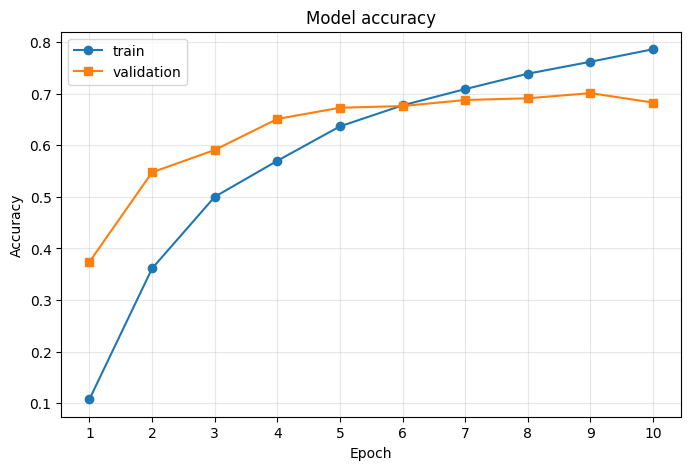

85/85 ━━━━━━━━━━━━━━━━━━━━ 19s 208ms/step - accuracy: 0.9440 - loss: 0.3232
91/91 ━━━━━━━━━━━━━━━━━━━━ 41s 452ms/step - accuracy: 0.7135 - loss: 1.0241
Dokładność na zbiorze treningowym: 0.9440 (94.40%)
Dokładność na zbiorze testowym: 0.7135 (71.35%)


In [7]:
# Niezbędne importy
from tensorflow.keras.optimizers import Adam
import matplotlib.pyplot as plt

# Kompilacja z uruchomieniem treningu
NB_EPOCH = 10
VERBOSE = 1
OPTIMIZER = Adam()
LOSS = "sparse_categorical_crossentropy"

model.compile(loss=LOSS, optimizer=OPTIMIZER, metrics=["accuracy"])

history = model.fit(
    train_ds,
    epochs=NB_EPOCH,
    verbose=VERBOSE,
    validation_data=val_ds
)

# Rysowanie wykresu dokładności
# Numeracja epok
epochs_range = range(1, len(history.history["accuracy"]) + 1)

# Wykres
plt.figure(figsize=(8, 5))
plt.plot(epochs_range, history.history["accuracy"], marker="o")
plt.plot(epochs_range, history.history["val_accuracy"], marker="s")
plt.title("Model accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.xticks(epochs_range)
plt.legend(["train", "validation"],loc="upper left")
plt.grid(True, alpha=0.3)
plt.show()

# Dokładność na zbiorze treningowym i testowym
_, acc_train = model.evaluate(train_ds, verbose=VERBOSE)
_, acc_test = model.evaluate(test_ds, verbose=VERBOSE)
print(f"Dokładność na zbiorze treningowym: {acc_train:.4f} ({acc_train*100:.2f}%)")
print(f"Dokładność na zbiorze testowym: {acc_test:.4f} ({acc_test*100:.2f}%)")

91/91 ━━━━━━━━━━━━━━━━━━━━ 27s 224ms/step


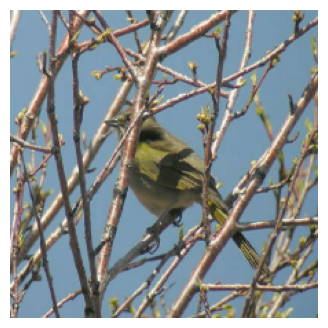

Original class number: 147
Original object: Green_tailed_Towhee
Detected class number: 155
Detected object: White_eyed_Vireo
Confidence: 0.25157874822616577
----------------------------------------


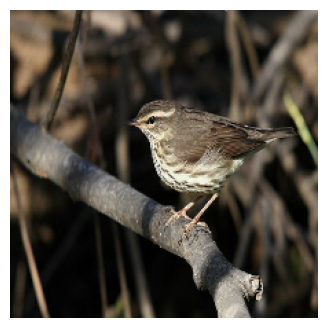

Original class number: 182
Original object: Northern_Waterthrush
Detected class number: 183
Detected object: Louisiana_Waterthrush
Confidence: 0.48329871892929077
----------------------------------------


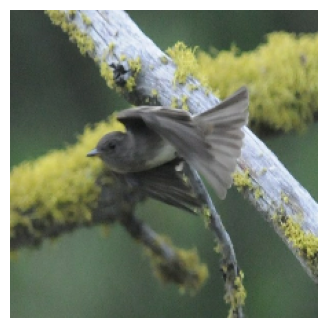

Original class number: 101
Original object: Western_Wood_Pewee
Detected class number: 8
Detected object: Brewer_Blackbird
Confidence: 0.1397780179977417
----------------------------------------


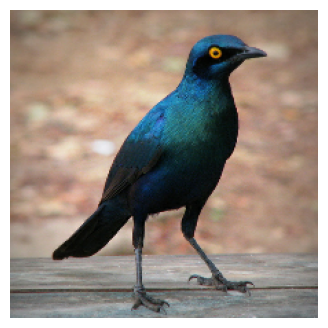

Original class number: 133
Original object: Cape_Glossy_Starling
Detected class number: 133
Detected object: Cape_Glossy_Starling
Confidence: 0.9578068852424622
----------------------------------------


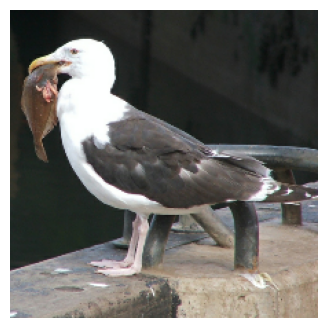

Original class number: 61
Original object: Herring_Gull
Detected class number: 58
Detected object: California_Gull
Confidence: 0.17827638983726501
----------------------------------------
Tablica pomyłek:
[[24  0  6]
 [ 1 22  3]
 [ 2  1 25]]


In [8]:
# Niezbędne importy
import numpy as np
import random
from sklearn.metrics import confusion_matrix

# Pobranie prawdziwych etykiet
test_labels = np.array([int(lbl.numpy()) for _, lbl in test_ds.unbatch()])
y_prob = model.predict(test_ds, verbose=VERBOSE)
y_pred = np.argmax(y_prob, axis=1)

# Losowanie 5 przykładowych zdjęć bez ładowania całego zbioru do pamięci
random.seed(42)
sample_indices = sorted(random.sample(range(len(test_labels)), 5))

selected_images = {}
for current_idx, (img_t, _) in enumerate(test_ds.unbatch()):
    if current_idx in sample_indices:
        selected_images[current_idx] = img_t.numpy()
        if len(selected_images) == len(sample_indices):
            break

# Wyświetlenie 5 zdjęć
for idx in sample_indices:
    img = selected_images[idx]
    true_id = int(test_labels[idx])
    pred_id = int(y_pred[idx])
    confidence = float(np.max(y_prob[idx]))

    plt.figure(figsize=(4, 4))
    plt.imshow(img.astype("uint8"))
    plt.axis("off")
    plt.show()
    plt.close()

    print("Original class number:", true_id)
    print("Original object:", bird_species[true_id])
    print("Detected class number:", pred_id)
    print("Detected object:", bird_species[pred_id])
    print("Confidence:", confidence)
    print("-" * 40)

# Tablica pomyłek
subspecies = [
    "Black_footed_Albatross",
    "Laysan_Albatross",
    "Sooty_Albatross"
]
subspecies_ids = [bird_species.index(name) for name in subspecies]

full_cm = confusion_matrix(
    test_labels,
    y_pred,
    labels=np.arange(len(bird_species))
)
sub_cm = full_cm[np.ix_(subspecies_ids, subspecies_ids)]

print("Tablica pomyłek:")
print(sub_cm)